Plotting the processed data to visualize the steps.

Author: Tayler LaSharr

Date: September 2024

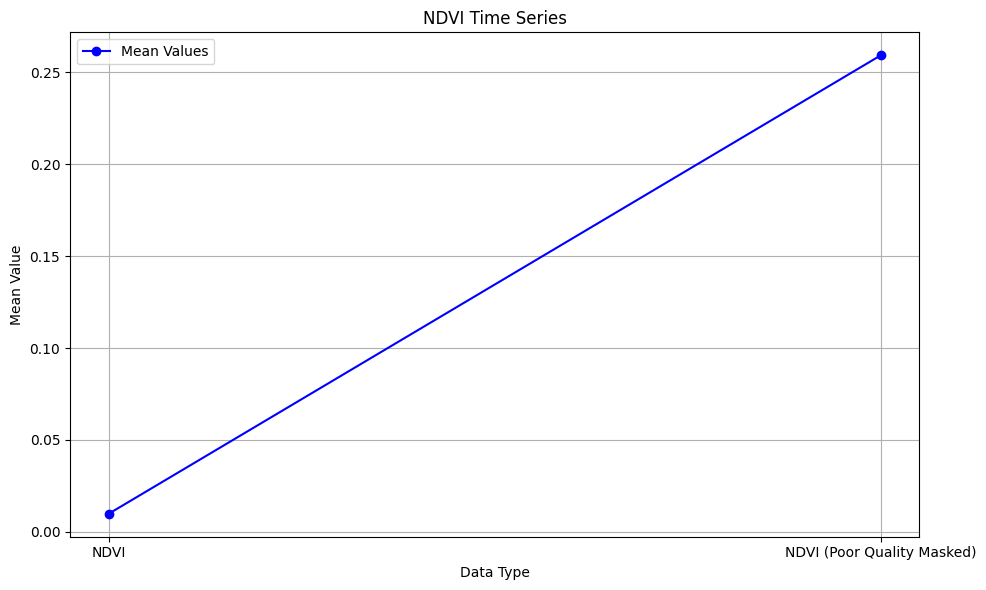

In [2]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import os


# Define the directory where the TIFFs are saved
tiff_dir = r'H:\My Drive\DroughtSurfing'

# Define file paths for the exported GeoTIFFs
ndvi_path = os.path.join(tiff_dir, 'viirs_ndvi.tif')
ndvi_filtered_path = os.path.join(tiff_dir, 'viirs_ndvi_filtered.tif')
ndvi_corrected_path = os.path.join(tiff_dir, 'viirs_ndvi_corrected.tif')
ndvi_smoothed_path = os.path.join(tiff_dir, 'smoothed_ndvi.tif')

# Function to read a GeoTIFF and compute the mean value of the raster data
def read_geotiff_mean(file_path):
    with rasterio.open(file_path) as src:
        data = src.read(1)  # Read the first band
        mask = src.dataset_mask()  # Get the valid data mask
        valid_data = np.ma.masked_array(data, mask == 0)  # Mask invalid data
        mean_value = valid_data.mean()  # Compute mean of the valid data
    return mean_value

# Read the mean values from the TIFF files
ndvi_mean = read_geotiff_mean(ndvi_path)
ndvi_filtered_mean = read_geotiff_mean(ndvi_filtered_path)
# ndvi_corrected_mean = read_geotiff_mean(ndvi_corrected_path)
# ndvi_smoothed_mean = read_geotiff_mean(ndvi_smoothed_path)

# Prepare data for plotting
time_steps = ['NDVI', 'NDVI (Poor Quality Masked)'] #, 'NDVI (Winter Processing)', 'NDVI (Smoothed)']
mean_values = [ndvi_mean, ndvi_filtered_mean] #, ndvi_corrected_mean, ndvi_smoothed_mean]

# Plot the time series on the same figure
plt.figure(figsize=(10, 6))
plt.plot(time_steps, mean_values, marker='o', linestyle='-', color='b', label='Mean Values')
plt.title('NDVI Time Series')
plt.xlabel('Data Type')
plt.ylabel('Mean Value')
plt.grid(True)
plt.legend()
plt.tight_layout()

# Show the plot
plt.show()